# Mini Project: Regression Algorithms Exploration
## Linear Regression & Polynomial Regression on the Medical Cost (Insurance) Dataset

## 1. Introduction

Health insurers need to estimate how much a person is likely to cost them so that premiums can be set fairly. In this mini project we use the **Medical Cost Personal Dataset** (Kaggle) to predict the **individual medical expenses billed by health insurance** from a handful of personal attributes.

**Goals**
- Explain how **Linear Regression** and **Polynomial Regression** work, when to use them, and their strengths and limits.
- Explore the data (EDA) and prepare it for modelling.
- Train both models with **Python and Scikit-learn**, evaluate them with MAE, MSE, RMSE and R², and **interpret** the results.
- Bonus: tune the polynomial degree and compare the two models.

**Prediction task:** predict the insurance cost (the `expenses` column; the project brief calls it *charges*, it is the same target) from `age`, `sex`, `bmi`, `children`, `smoker` and `region`.

**Notebook outline**
1. Introduction  2. Algorithm explanation  3. Dataset exploration (EDA)  4. Data preprocessing  5. Model training  6. Model evaluation  7. Bonus: tuning and comparison  8. Conclusion

## 2. Algorithm Explanation

### 2.1 Linear Regression

**What is it?** A supervised learning algorithm that predicts a continuous target as a **weighted sum of the input features** plus a constant (intercept).

**How does it work?** For features $x_1,\dots,x_p$ the model is

$$\hat{y} = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots + \beta_p x_p$$

Ordinary Least Squares (OLS) chooses the coefficients that minimise the sum of squared residuals on the training data:

$$\min_{\beta}\ \sum_{i=1}^{n} \left(y_i - \hat{y}_i\right)^2$$

Each coefficient $\beta_j$ reads as: *"holding the other features fixed, a one-unit increase in $x_j$ changes the prediction by $\beta_j$."*

**When should it be used?**
- The relationship between features and target is roughly linear (or can be made so).
- You need an **interpretable** model or a fast, simple baseline.

| Advantages | Limitations |
|---|---|
| Very fast, no hyperparameters | Can only draw straight-line (flat) relationships |
| Highly interpretable coefficients | Cannot capture interactions unless you add them by hand |
| Strong baseline, works with little data | Sensitive to outliers (squared error) |
| Closed-form solution, no convergence issues | Assumes linearity, independent errors and constant error variance; suffers if features are highly correlated |

### 2.2 Polynomial Regression

**What is it?** Linear Regression applied to an **expanded set of features** made of powers and products of the original ones. It stays *linear in the coefficients*, but the fitted function becomes *curved*.

**How does it work?** `PolynomialFeatures(degree=d)` creates all terms up to degree $d$. For two features and degree 2:

$$[x_1, x_2] \;\rightarrow\; [x_1,\; x_2,\; x_1^2,\; x_1 x_2,\; x_2^2]$$

and a normal linear regression is then fitted on these new columns:

$$\hat{y} = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \beta_3 x_1^2 + \beta_4 x_1 x_2 + \beta_5 x_2^2$$

The **degree** controls flexibility: degree 1 is plain linear regression; higher degrees fit more complex curves but risk **overfitting**. The product terms (such as $x_1x_2$) are **interaction effects**: the impact of one feature depends on the value of another.

**When should it be used?**
- The scatter plots show a **curved** trend, or one feature's effect depends on another.
- You want more flexibility than a straight line while keeping a simple, linear-model framework.

| Advantages | Limitations |
|---|---|
| Captures curvature and interactions | Number of features explodes with degree and feature count |
| Still fast and uses the same OLS machinery | High degrees overfit and extrapolate wildly outside the training range |
| Degree gives a simple "complexity knob" | Coefficients are harder to interpret |
| | Features should be scaled; the degree must be chosen with validation |

## 3. Dataset Exploration (EDA)

In [82]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

### 3.1 Dataset structure

In [83]:
from pathlib import Path

# Works in Colab (upload insurance.csv) and with the supplied project files.
if Path("insurance.csv").exists():
    data_path = "insurance.csv"
elif Path("insurance(2).csv").exists():
    data_path = "insurance(2).csv"
else:
    data_path = "/mnt/data/insurance(2).csv"

df = pd.read_csv("insurance.csv")
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (1338, 7)


,age,sex,bmi,children,smoker,region,expenses
0,19,female,27.9,0,yes,southwest,16884.92
1,18,male,33.8,1,no,southeast,1725.55
2,28,male,33.0,3,no,southeast,4449.46
3,33,male,22.7,0,no,northwest,21984.47
4,32,male,28.9,0,no,northwest,3866.86


In [84]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   expenses  1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [85]:
df.describe().round(2)

,age,bmi,children,expenses
count,1338.00,1338.00,1338.00,1338.00
mean,39.21,30.67,1.09,13270.42
std,14.05,6.10,1.21,12110.01
min,18.00,16.00,0.00,1121.87
25%,27.00,26.30,0.00,4740.29
50%,39.00,30.40,1.00,9382.03
75%,51.00,34.70,2.00,16639.92
max,64.00,53.10,5.00,63770.43


### 3.2 Features and target variable

In [86]:
target = "expenses"
numeric_features = ["age", "bmi", "children"]
categorical_features = ["sex", "smoker", "region"]

print("Target:", target)
print("Numeric Features:", numeric_features)
print("Categorical Features:", categorical_features)
features = numeric_features + categorical_features

Target: expenses
Numeric Features: ['age', 'bmi', 'children']
Categorical Features: ['sex', 'smoker', 'region']


### 3.3 Missing values and duplicates

In [87]:
print("Missing values")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Missing values
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
expenses    0
dtype: int64

Duplicate rows: 1


In [88]:
df = df.drop_duplicates().reset_index(drop=True)

**Data quality:** No missing values were found. One fully duplicated row was removed before the split. Rows flagged as outliers are retained because they may be valid high medical costs or BMI measurements; the IQR rule does not prove an error.

### 3.4 Visualising the data

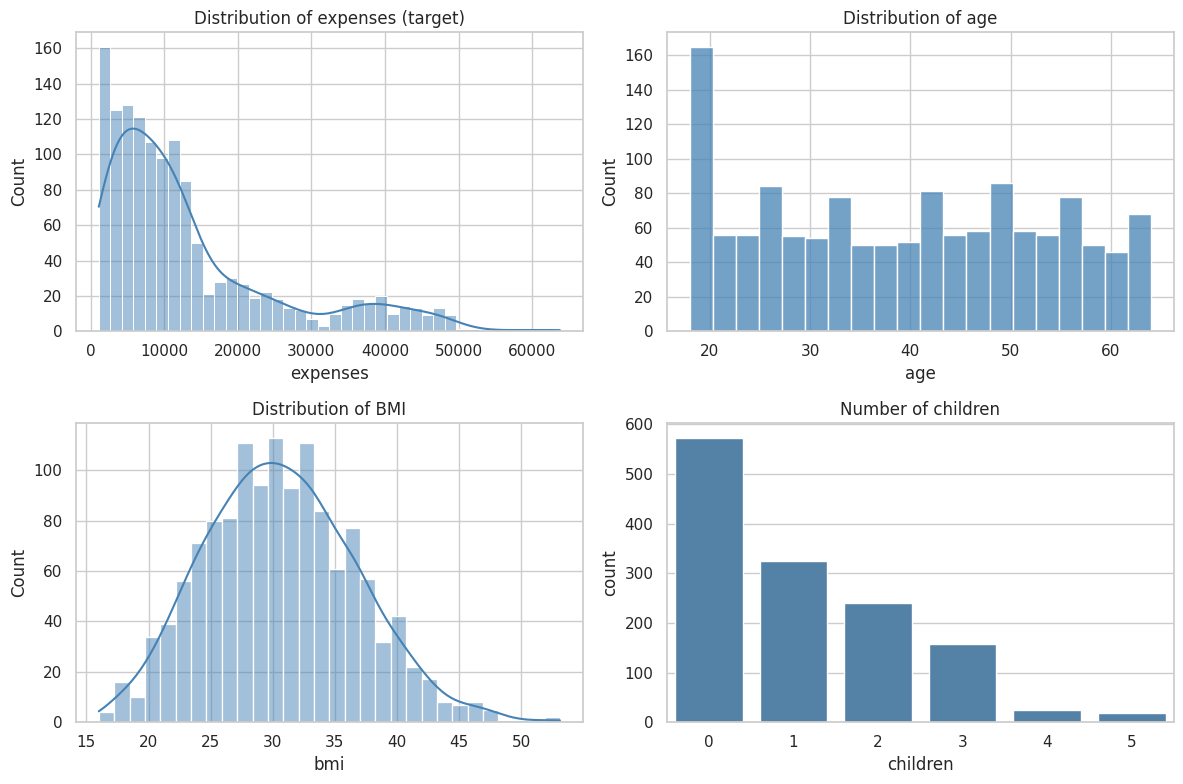

In [89]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
sns.histplot(df["expenses"], bins=40, kde=True, color="steelblue", ax=axes[0, 0]).set_title("Distribution of expenses (target)")
sns.histplot(df["age"], bins=20, color="steelblue", ax=axes[0, 1]).set_title("Distribution of age")
sns.histplot(df["bmi"], bins=30, kde=True, color="steelblue", ax=axes[1, 0]).set_title("Distribution of BMI")
sns.countplot(x="children", data=df, color="steelblue", ax=axes[1, 1]).set_title("Number of children")
plt.tight_layout()
plt.show()

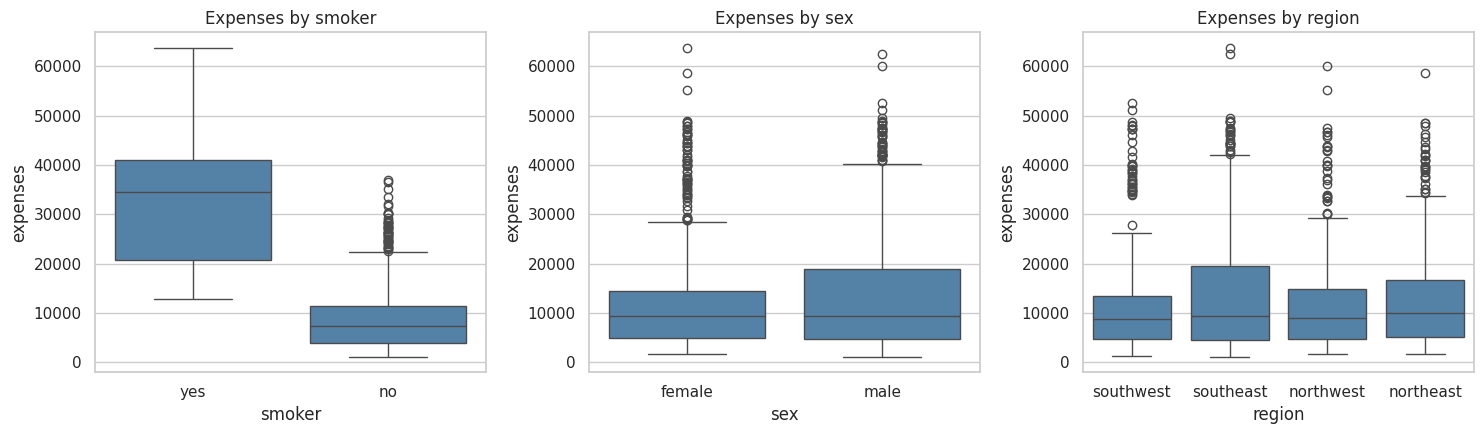

In [90]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, col in zip(axes, ["smoker", "sex", "region"]):
    sns.boxplot(x=col, y="expenses", data=df, color="steelblue", ax=ax)
    ax.set_title(f"Expenses by {col}")
plt.tight_layout()
plt.show()

In [91]:
Q1 = df["expenses"].quantile(0.25)
Q3 = df["expenses"].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
expense_outliers = df[(df["expenses"] < lower) | (df["expenses"] > upper)]
print("Expenses outliers:", len(expense_outliers))

Expenses outliers: 139


In [92]:
Q1 = df["bmi"].quantile(0.25)
Q3 = df["bmi"].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

bmi_outliers = df[(df["bmi"] < lower) | (df["bmi"] > upper)]

print("Lower limit:", lower)
print("Upper limit:", upper)
print("Number of BMI outliers:", len(bmi_outliers))

Lower limit: 13.699999999999998
Upper limit: 47.300000000000004
Number of BMI outliers: 9


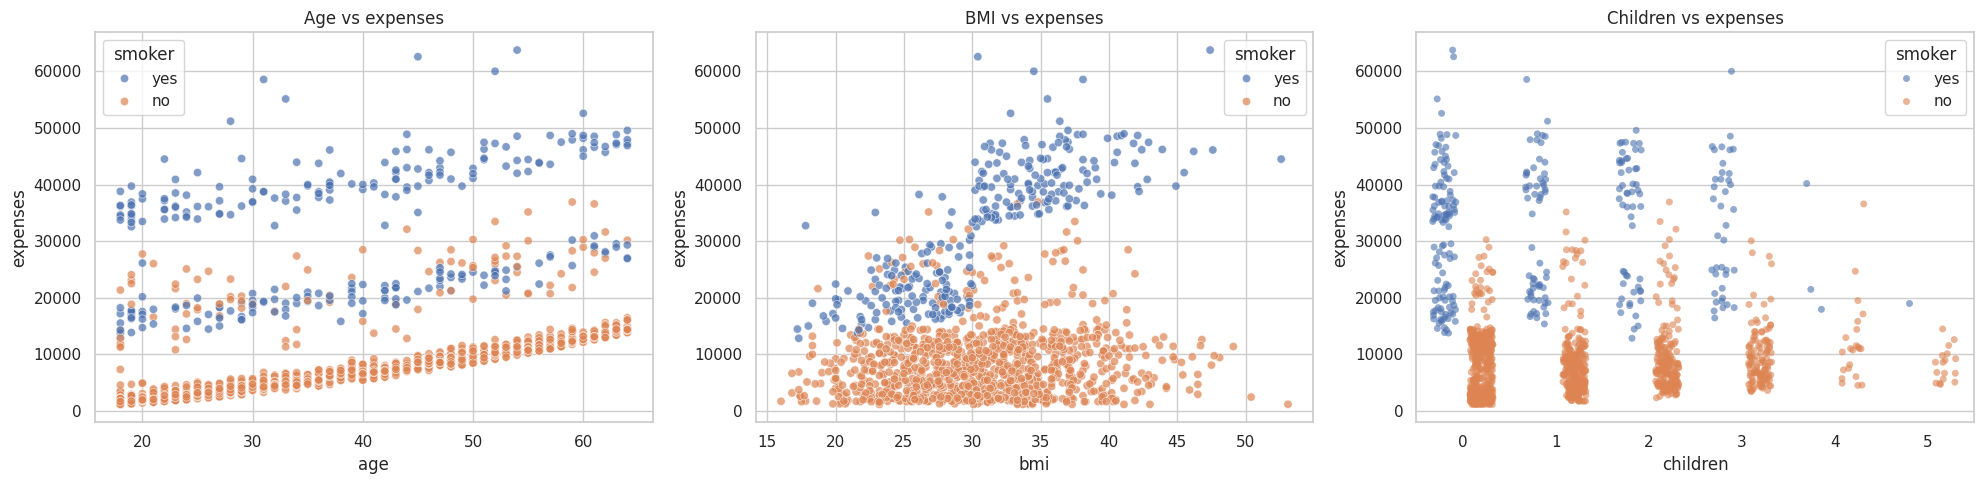

In [234]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
sns.scatterplot(x="age", y="expenses", hue="smoker", data=df, alpha=0.7, ax=axes[0])
axes[0].set_title("Age vs expenses")
sns.scatterplot(x="bmi", y="expenses", hue="smoker", data=df, alpha=0.7, ax=axes[1])
axes[1].set_title("BMI vs expenses")
sns.stripplot(x="children", y="expenses", hue="smoker", data=df, alpha=0.6,
              dodge=True, jitter=0.25, ax=axes[2])
axes[2].set_title("Children vs expenses")
plt.tight_layout()
plt.show()

In [96]:
print(df["children"].corr(df["expenses"]))

0.06738935382976857


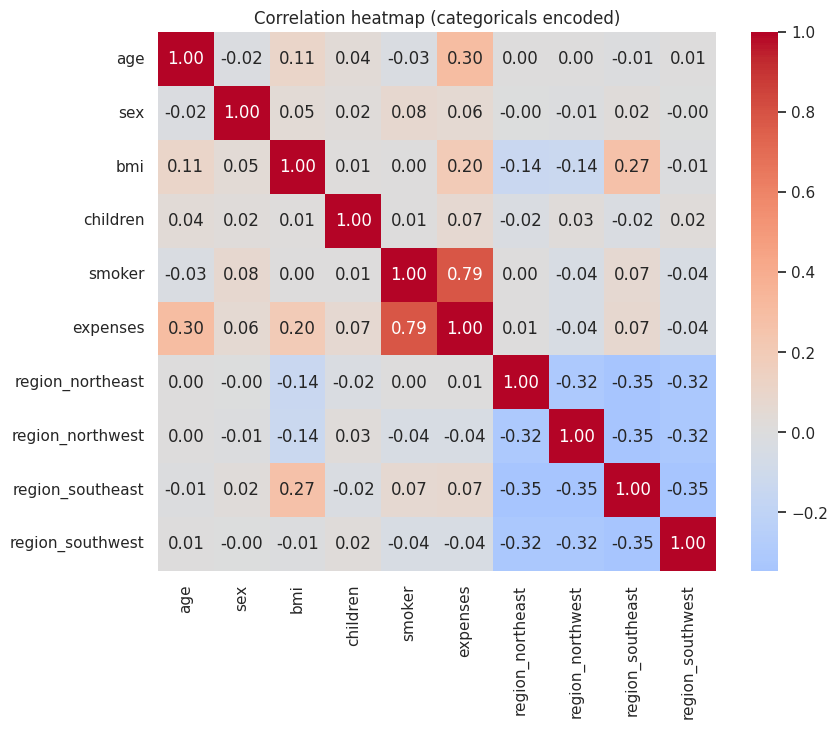


Correlation with expenses:
smoker              0.79
age                 0.30
bmi                 0.20
region_southeast    0.07
children            0.07
sex                 0.06
region_northeast    0.01
region_northwest   -0.04
region_southwest   -0.04
Name: expenses, dtype: float64


In [97]:
df_enc = df.copy()
df_enc["sex"] = (df_enc["sex"] == "male").astype(int)
df_enc["smoker"] = (df_enc["smoker"] == "yes").astype(int)
df_enc = pd.get_dummies(df_enc, columns=["region"], dtype=int)

plt.figure(figsize=(9, 7))
sns.heatmap(df_enc.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap (categoricals encoded)")
plt.show()
print("\nCorrelation with expenses:")
print(df_enc.corr()["expenses"].drop("expenses").sort_values(ascending=False).round(2))

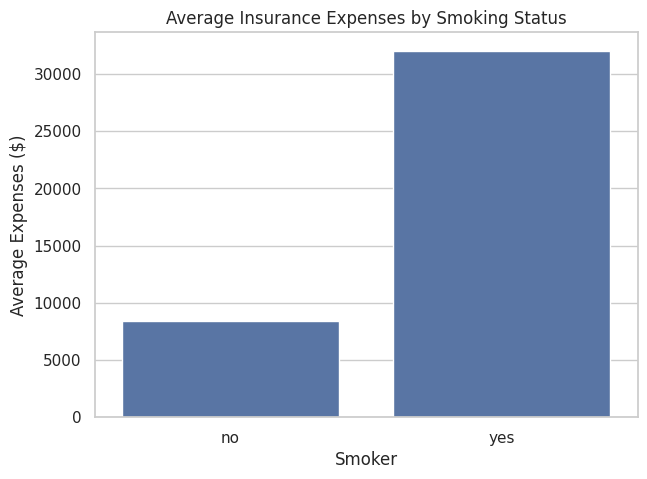

smoker
no      8441.0
yes    32050.0
Name: expenses, dtype: float64


In [236]:
smoker_avg = df.groupby("smoker")["expenses"].mean()

plt.figure(figsize=(7, 5))

sns.barplot(x=smoker_avg.index, y=smoker_avg.values)

plt.title("Average Insurance Expenses by Smoking Status")
plt.xlabel("Smoker")
plt.ylabel("Average Expenses ($)")

plt.show()
print(df.groupby("smoker")["expenses"].mean().round(0))

### 3.5 EDA takeaways
- `expenses` is right-skewed, with a smaller group of high-cost records.
- Smoking status has a strong association with expenses in this dataset, especially for higher BMI.
- The relationship of `children` with expenses is weak on its own; association is not causation.
- IQR detects unusual expenses/BMI values

## 4. Data Preprocessing

1. Remove the exact duplicate (already done) and check for missing values.
2. Encode `sex`, `smoker` and `region` as dummy variables.
3. Split 80% training / 20% testing, using `random_state=42`.
4. Fit `StandardScaler` Both models use these scaled inputs for a consistent comparison.



In [227]:
X = pd.get_dummies(df.drop(columns=[target]), drop_first=True, dtype=int)
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2
)
print("Train:", X_train.shape, "Test:", X_test.shape)
print("Features:", X.columns.tolist())

Train: (1069, 8) Test: (268, 8)
Features: ['age', 'bmi', 'children', 'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest']


In [228]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("Scaled train shape:", X_train_scaled.shape)
print("Scaled test shape:", X_test_scaled.shape)

Scaled train shape: (1069, 8)
Scaled test shape: (268, 8)


## 5. Model Training

### 5.1 Linear Regression

In [229]:
linear_model = LinearRegression()
linear_model.fit(X_train_scaled, y_train)
y_pred_linear = linear_model.predict(X_test_scaled)

### 5.2 Polynomial Regression


In [230]:
poly = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly = poly.fit_transform(X_train_scaled)
X_test_poly = poly.transform(X_test_scaled)

poly_model = LinearRegression()
poly_model.fit(X_train_poly, y_train)
y_pred_poly = poly_model.predict(X_test_poly)


## 6. Model Evaluation

Both models are now evaluated on the **held-out test set** with MAE, MSE, RMSE and R².


In [231]:
results = []
for name, model, X_tr, X_te in [
    ("Linear Regression", linear_model, X_train_scaled, X_test_scaled),
    ("Polynomial Regression", poly_model, X_train_poly, X_test_poly)
]:

    for split, X_data, y_data in [
        ("Train", X_tr, y_train),
        ("Test", X_te, y_test)
    ]:
        pred = model.predict(X_data)

        results.append({
            "Model": name,
            "Split": split,
            "MAE": mean_absolute_error(y_data, pred),
            "MSE": mean_squared_error(y_data, pred),
            "RMSE": np.sqrt(mean_squared_error(y_data, pred)),
            "R2": r2_score(y_data, pred)
        })

results_df = pd.DataFrame(results)
display(results_df.round(2).style.format({
    "MAE": "{:,.2f}",
    "MSE": "{:,.2f}",
    "RMSE": "{:,.2f}",
    "R2": "{:.3f}"
}))

,Model,Split,MAE,MSE,RMSE,R2
0,Linear Regression,Train,"4,299.42","38,464,169.20","6,201.95",0.730
1,Linear Regression,Test,"3,873.85","29,338,868.13","5,416.54",0.820
2,Polynomial Regression,Train,"2,956.10","23,666,499.23","4,864.82",0.840
3,Polynomial Regression,Test,"2,742.11","17,603,038.68","4,195.60",0.890


In [232]:
test_results = results_df[results_df["Split"] == "Test"]
display(test_results.round(2))

,Model,Split,MAE,MSE,RMSE,R2
1,Linear Regression,Test,3873.85,29338868.13,5416.54,0.82
3,Polynomial Regression,Test,2742.11,17603038.68,4195.60,0.89


### 6.1 Actual vs predicted (test set)

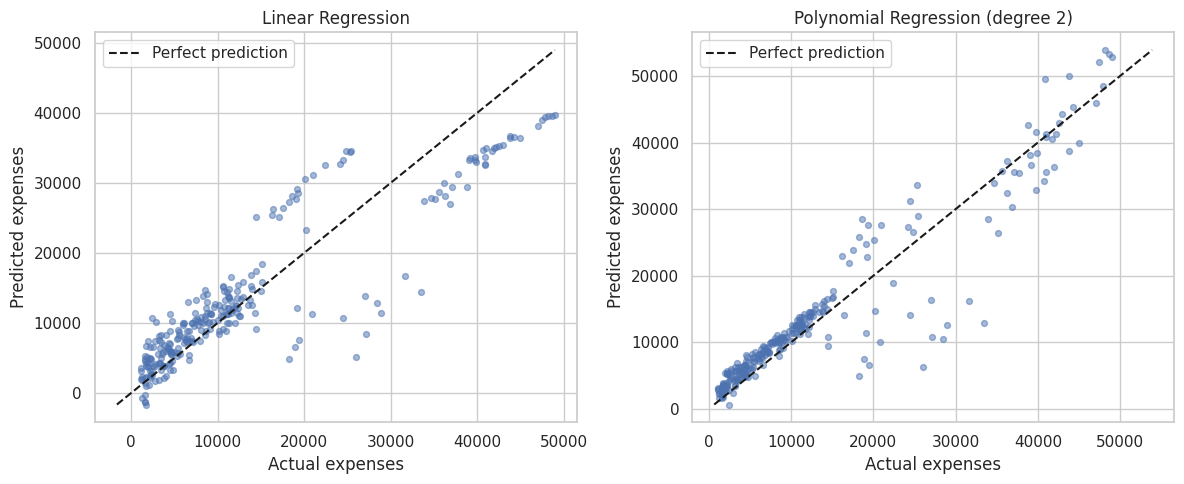

In [237]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, title, pred in zip(
    axes,
    ["Linear Regression", "Polynomial Regression (degree 2)"],
    [y_pred_linear, y_pred_poly]
):
    ax.scatter(y_test, pred, alpha=0.5, s=18)
    bounds = [min(y_test.min(), pred.min()), max(y_test.max(), pred.max())]
    ax.plot(bounds, bounds, "k--", label="Perfect prediction")
    ax.set_title(title)
    ax.set_xlabel("Actual expenses")
    ax.set_ylabel("Predicted expenses")
    ax.legend()
plt.tight_layout()
plt.show()

### Actual vs Predicted Analysis

**Linear Regression:**
Many points are far from the perfect prediction line, especially for high expenses.

**Polynomial Regression:**
Most points are closer to the perfect prediction line, indicating better predictions.


## 7. Bonus

To better understand the models and improve their performance, we conducted two additional experiments.

### 1. Testing Different Polynomial Degrees

We experimented with different polynomial degrees, from **1 to 5**, to determine which degree provided better predictions.

- Degree 2 showed the best performance among the degrees we tested.
- The other degrees generally produced less favorable evaluation results.
- Increasing the polynomial degree did not necessarily improve the model's performance and could increase the risk of overfitting.

**Finding:** Degree 2 provided a good balance between model complexity and prediction accuracy.

### 2. Investigating the Impact of Removing Outliers

We also tested how removing outliers would affect model performance.

- Polynomial Regression's R² decreased from approximately **0.88 to 0.50–0.56** after removing outliers.
- This experiment suggested that removing extreme values may have removed useful information about insurance expenses.

**Finding:** Keeping valid extreme observations may help preserve important information and relationships in the dataset.

## 8. Conclusion

This project compared **Linear Regression** and **Polynomial Regression (degrees)** to predict medical insurance expenses.

### Model Performance

- **Linear Regression:** Achieved an R² of 0.82 and an RMSE of 5416.54 on the test set.
- **Polynomial Regression:** Achieved a higher R² of 0.89 and a lower RMSE of 4195.60 on the test set.

### Key Findings

- Polynomial Regression performed better than Linear Regression.
- The Actual vs Predicted plots showed that Polynomial Regression predictions were generally closer to the actual values.
- The Residual plots showed that Polynomial Regression had smaller prediction errors overall, although some large errors remained.
- The results suggest that nonlinear relationships and interactions between features are important for predicting insurance expenses.

### Final Conclusion

**Polynomial Regression (degree 2) was the better-performing model** for predicting medical insurance expenses based on the test results. It achieved higher prediction accuracy and captured more complex relationships in the dataset compared to Linear Regression.